# Source Mixing and Delay Geometry

Compare channels that observe a shared two-mode source with channels that mix two independent single-mode sources. Visualize their delay embeddings and measure pairwise Procrustes disparity using time-aligned samples.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import neuralfieldmanifold as nfm

fs = 500
n_samples = 5000
source = nfm.simulation.oscillatory_ar([10, 23], [.995, .990], sampling_rate_hz=fs,
                                      n_samples=n_samples, noise_std=.03, seed=42,
                                      random_initialization=True)
rng = np.random.default_rng(0)
shared = np.array([source + .05 * rng.normal(size=n_samples) for _ in range(8)])
first = nfm.simulation.oscillatory_ar([10], [.995], sampling_rate_hz=fs,
                                     n_samples=n_samples, noise_std=.03, seed=100)
second = nfm.simulation.oscillatory_ar([23], [.995], sampling_rate_hz=fs,
                                      n_samples=n_samples, noise_std=.03, seed=200)
weights = nfm.simulation.mixing_matrix(n_sensors=8, n_sources=2, spatial_spread=.3)
mixed = weights @ np.stack([first, second]) + .05 * rng.normal(size=(8, n_samples))


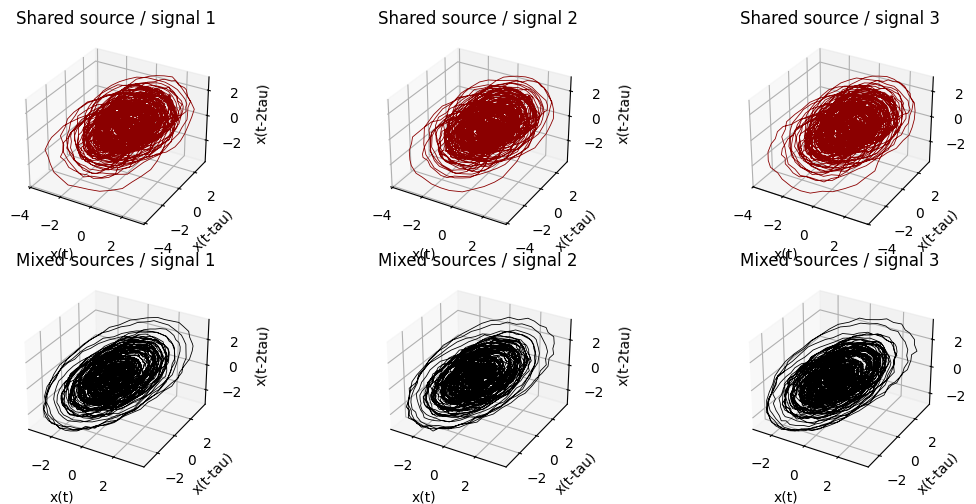

In [2]:
fig = plt.figure(figsize=(12, 5))
for row, signals in enumerate([shared, mixed]):
    for col in range(3):
        cloud = nfm.embedding.delay(signals[col].astype(np.float32), dimension=3, tau_samples=5)
        ax = fig.add_subplot(2, 3, row * 3 + col + 1, projection='3d')
        nfm.plotting.embedding(cloud, ax=ax, color='darkred' if row == 0 else 'black')
        ax.set_title(('Shared source' if row == 0 else 'Mixed sources') + f' / signal {col + 1}')
plt.tight_layout()
plt.show()


In [3]:
for name, signals in [('shared', shared), ('mixed', mixed)]:
    disparity = nfm.geometry.pairwise_disparity(signals.astype(np.float32), dimension=3,
                                               tau_samples=5, target_points=2000)
    print(name, disparity.mean, disparity.standard_deviation)


shared 0.005019150953359793 0.00010608010942999688
mixed 0.5407843471484057 0.41723004723989504


## Interpretation

Procrustes disparity measures differences in trajectory shape after translation, scaling, and orthogonal alignment. Compare the two source constructions in this controlled example; the statistic alone does not establish whether real channels share a physical source.
